In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import seaborn as sns
from scipy import stats
import random
import itertools

In [2]:
import scHPT

In [3]:
import scanpy as sc
import anndata as ad

In [4]:
import matplotlib.colors as mplc
import matplotlib
import matplotlib.patches as mpatches
from matplotlib.offsetbox import (DrawingArea, OffsetImage,AnnotationBbox)

# Heterogeneous cell cycle effects

Data were downloaded from https://figshare.com/s/139f64b495dea9d88c70. [McFarland, J.M., Paolella, B.R., Warren, A. et al. Nat Commun 2020.]

# 1.1 Nutlin

In [23]:
nutlin_adata=sc.read('data/Idasanutlin_24hr_expt1_processed.h5ad')
type_full_name=list(nutlin_adata.obs.cell_type.cat.categories)
type_simple_name=[i.split('_')[0] for i in type_full_name]
type_conv_dict=dict(zip(type_full_name,type_simple_name))
nutlin_adata.obs.cell_type.cat.rename_categories(type_conv_dict,inplace=True)
# annotate cell cycles
cell_cycle_genes = [x.strip() for x in open('regev_lab_cell_cycle_genes.txt')]
s_genes = cell_cycle_genes[:43]
g2m_genes = cell_cycle_genes[43:]
sc.tl.score_genes_cell_cycle(nutlin_adata, s_genes=s_genes, g2m_genes=g2m_genes)
# cell cycle phase markers
cell_cycle_marker = pd.read_excel('cellcyclemarkers.xlsx')
cell_cycle_marker_dict={}
for stage in cell_cycle_marker.columns:
    markerswonan=[x for x in cell_cycle_marker[stage].tolist() if str(x)!='nan']
    markers=list(set([x.strip() for x in markerswonan]) & set(nutlin_adata.var_names))
    cell_cycle_marker_dict[stage]=markers
s_geneset=cell_cycle_marker_dict['S']
g2m_geneset=cell_cycle_marker_dict['G2/M']

C:\Users\17794\AppData\Roaming\Python\Python39\site-packages\pandas\core\arrays\categorical.py:2631: FutureWarning: The `inplace` parameter in pandas.Categorical.rename_categories is deprecated and will be removed in a future version. Removing unused categories will always return a new Categorical object.
  res = method(*args, **kwargs)


In [24]:
# define Y = S phase markers
nutlin_adata.obs['S_markers'] = nutlin_adata[:,s_geneset].X.copy().mean(axis=1).flatten()

In [26]:
final_res_df=scHPT.permute_test_group(adata=nutlin_adata, Y_column='S_markers', T_column='condition',
                                      group_column='cell_type', pert_name='nutlin', ctrl_name='control',
                                      n_perm=1000, verbose=True)

The number of cells in 1 groups is less than threshold 50
Finish permutation : 0
Finish permutation : 100
Finish permutation : 200
Finish permutation : 300
Finish permutation : 400
Finish permutation : 500
Finish permutation : 600
Finish permutation : 700
Finish permutation : 800
Finish permutation : 900


In [42]:
tau_sig_list=[]
p_val_sig_list=[]
g1_delta_list=[]
s_delta_list=[]
g2m_delta_list=[]
for i in range(len(final_res_df)):
    lb,ub=stats.norm.interval(1-0.05, loc=final_res_df.iloc[i,:]['tau_hat'], scale=final_res_df.iloc[i,:]['tau_sd'])
    if lb<=0 and ub>0:
        tau_sig_list.append(0)
    else:
        tau_sig_list.append(1)
    if final_res_df.iloc[i,:]['p_val']<=0.1:
        p_val_sig_list.append(1)
    else:
        p_val_sig_list.append(0)
    cell_line=final_res_df.iloc[i,:]['group']
    obs_cell_line=nutlin_adata[nutlin_adata.obs.cell_type==cell_line].obs
    obs_ctrl_cell_line=obs_cell_line[obs_cell_line.condition=='control']
    g1_ctrl=len(obs_ctrl_cell_line[obs_ctrl_cell_line.phase=='G1'])/len(obs_ctrl_cell_line)
    s_ctrl=len(obs_ctrl_cell_line[obs_ctrl_cell_line.phase=='S'])/len(obs_ctrl_cell_line)
    g2m_ctrl=len(obs_ctrl_cell_line[obs_ctrl_cell_line.phase=='G2M'])/len(obs_ctrl_cell_line)
    obs_drug_cell_line=obs_cell_line[obs_cell_line.condition!='control']
    g1_drug=len(obs_drug_cell_line[obs_drug_cell_line.phase=='G1'])/len(obs_drug_cell_line)
    s_drug=len(obs_drug_cell_line[obs_drug_cell_line.phase=='S'])/len(obs_drug_cell_line)
    g2m_drug=len(obs_drug_cell_line[obs_drug_cell_line.phase=='G2M'])/len(obs_drug_cell_line)
    g1_delta_list.append(g1_drug-g1_ctrl)
    s_delta_list.append(s_drug-s_ctrl)
    g2m_delta_list.append(g2m_drug-g2m_ctrl)
    #err_list.append(stats.norm.interval(1-0.05, loc=0, scale=final_res_df.iloc[i,:]['tau_sd'])[1])
final_res_df['95_tau_sig']=tau_sig_list
final_res_df['95_p_val_sig']=p_val_sig_list
final_res_df['g1_delta']=g1_delta_list
final_res_df['s_delta']=s_delta_list
final_res_df['g2m_delta']=g2m_delta_list
final_res_df.sort_values('tau_hat', inplace=True,ascending=True)

In [43]:
final_res_df.to_csv('cell_cycle_hetero_nutlin_S.csv')

# 1.2 Bortezomib

In [28]:
bortezomib_adata=sc.read('data/Bortezomib_24hr_expt1_processed.h5ad')
type_full_name=list(bortezomib_adata.obs.cell_type.cat.categories)
type_simple_name=[i.split('_')[0] for i in type_full_name]
type_conv_dict=dict(zip(type_full_name,type_simple_name))
bortezomib_adata.obs.cell_type.cat.rename_categories(type_conv_dict,inplace=True)
# annotate cell cycles
cell_cycle_genes = [x.strip() for x in open('regev_lab_cell_cycle_genes.txt')]
s_genes = cell_cycle_genes[:43]
g2m_genes = cell_cycle_genes[43:]
sc.tl.score_genes_cell_cycle(bortezomib_adata, s_genes=s_genes, g2m_genes=g2m_genes)
# cell cycle phase markers
cell_cycle_marker = pd.read_excel('cellcyclemarkers.xlsx')
cell_cycle_marker_dict={}
for stage in cell_cycle_marker.columns:
    markerswonan=[x for x in cell_cycle_marker[stage].tolist() if str(x)!='nan']
    markers=list(set([x.strip() for x in markerswonan]) & set(bortezomib_adata.var_names))
    cell_cycle_marker_dict[stage]=markers
s_geneset=cell_cycle_marker_dict['S']
g2m_geneset=cell_cycle_marker_dict['G2/M']

C:\Users\17794\AppData\Roaming\Python\Python39\site-packages\pandas\core\arrays\categorical.py:2631: FutureWarning: The `inplace` parameter in pandas.Categorical.rename_categories is deprecated and will be removed in a future version. Removing unused categories will always return a new Categorical object.
  res = method(*args, **kwargs)


In [29]:
# define Y = S phase markers
bortezomib_adata.obs['S_markers'] = bortezomib_adata[:,s_geneset].X.copy().mean(axis=1).flatten()

In [31]:
final_res_df=scHPT.permute_test_group(adata=bortezomib_adata, Y_column='S_markers', T_column='condition',
                                      group_column='cell_type', pert_name='Bortezomib', ctrl_name='control',
                                      n_perm=1000, verbose=True)

The number of cells in 8 groups is less than threshold 50
Finish permutation : 0
Finish permutation : 100
Finish permutation : 200
Finish permutation : 300
Finish permutation : 400
Finish permutation : 500
Finish permutation : 600
Finish permutation : 700
Finish permutation : 800
Finish permutation : 900


In [45]:
tau_sig_list=[]
p_val_sig_list=[]
g1_delta_list=[]
s_delta_list=[]
g2m_delta_list=[]
for i in range(len(final_res_df)):
    lb,ub=stats.norm.interval(1-0.05, loc=final_res_df.iloc[i,:]['tau_hat'], scale=final_res_df.iloc[i,:]['tau_sd'])
    if lb<=0 and ub>0:
        tau_sig_list.append(0)
    else:
        tau_sig_list.append(1)
    if final_res_df.iloc[i,:]['p_val']<=0.1:
        p_val_sig_list.append(1)
    else:
        p_val_sig_list.append(0)
    cell_line=final_res_df.iloc[i,:]['group']
    obs_cell_line=bortezomib_adata[bortezomib_adata.obs.cell_type==cell_line].obs
    obs_ctrl_cell_line=obs_cell_line[obs_cell_line.condition=='control']
    g1_ctrl=len(obs_ctrl_cell_line[obs_ctrl_cell_line.phase=='G1'])/len(obs_ctrl_cell_line)
    s_ctrl=len(obs_ctrl_cell_line[obs_ctrl_cell_line.phase=='S'])/len(obs_ctrl_cell_line)
    g2m_ctrl=len(obs_ctrl_cell_line[obs_ctrl_cell_line.phase=='G2M'])/len(obs_ctrl_cell_line)
    obs_drug_cell_line=obs_cell_line[obs_cell_line.condition!='control']
    g1_drug=len(obs_drug_cell_line[obs_drug_cell_line.phase=='G1'])/len(obs_drug_cell_line)
    s_drug=len(obs_drug_cell_line[obs_drug_cell_line.phase=='S'])/len(obs_drug_cell_line)
    g2m_drug=len(obs_drug_cell_line[obs_drug_cell_line.phase=='G2M'])/len(obs_drug_cell_line)
    g1_delta_list.append(g1_drug-g1_ctrl)
    s_delta_list.append(s_drug-s_ctrl)
    g2m_delta_list.append(g2m_drug-g2m_ctrl)
    #err_list.append(stats.norm.interval(1-0.05, loc=0, scale=final_res_df.iloc[i,:]['tau_sd'])[1])
final_res_df['95_tau_sig']=tau_sig_list
final_res_df['95_p_val_sig']=p_val_sig_list
final_res_df['g1_delta']=g1_delta_list
final_res_df['s_delta']=s_delta_list
final_res_df['g2m_delta']=g2m_delta_list
final_res_df.sort_values('tau_hat', inplace=True,ascending=True)

In [46]:
final_res_df.to_csv('cell_cycle_hetero_bortezomib_S.csv')

# 1.3 Trametinib

In [34]:
trametinib_adata=sc.read('data/Trametinib_24hr_expt1_processed.h5ad')
type_full_name=list(trametinib_adata.obs.cell_type.cat.categories)
type_simple_name=[i.split('_')[0] for i in type_full_name]
type_conv_dict=dict(zip(type_full_name,type_simple_name))
trametinib_adata.obs.cell_type.cat.rename_categories(type_conv_dict,inplace=True)
cell_cycle_genes = [x.strip() for x in open('regev_lab_cell_cycle_genes.txt')]
s_genes = cell_cycle_genes[:43]
g2m_genes = cell_cycle_genes[43:]
sc.tl.score_genes_cell_cycle(trametinib_adata, s_genes=s_genes, g2m_genes=g2m_genes)
cell_cycle_marker = pd.read_excel('cellcyclemarkers.xlsx')
cell_cycle_marker_dict={}
for stage in cell_cycle_marker.columns:
    markerswonan=[x for x in cell_cycle_marker[stage].tolist() if str(x)!='nan']
    markers=list(set([x.strip() for x in markerswonan]) & set(trametinib_adata.var_names))
    cell_cycle_marker_dict[stage]=markers
s_geneset=cell_cycle_marker_dict['S']
g2m_geneset=cell_cycle_marker_dict['G2/M']

C:\Users\17794\AppData\Roaming\Python\Python39\site-packages\pandas\core\arrays\categorical.py:2631: FutureWarning: The `inplace` parameter in pandas.Categorical.rename_categories is deprecated and will be removed in a future version. Removing unused categories will always return a new Categorical object.
  res = method(*args, **kwargs)


In [35]:
trametinib_adata.obs['S_markers'] = trametinib_adata[:,s_geneset].X.copy().mean(axis=1).flatten()

In [37]:
final_res_df=scHPT.permute_test_group(adata=trametinib_adata, Y_column='S_markers', T_column='condition',
                                      group_column='cell_type', pert_name='Trametinib', ctrl_name='control',
                                      n_perm=1000, verbose=True)

The number of cells in 1 groups is less than threshold 50
Finish permutation : 0
Finish permutation : 100
Finish permutation : 200
Finish permutation : 300
Finish permutation : 400
Finish permutation : 500
Finish permutation : 600
Finish permutation : 700
Finish permutation : 800
Finish permutation : 900


In [38]:
tau_sig_list=[]
p_val_sig_list=[]
g1_delta_list=[]
s_delta_list=[]
g2m_delta_list=[]
for i in range(len(final_res_df)):
    lb,ub=stats.norm.interval(1-0.05, loc=final_res_df.iloc[i,:]['tau_hat'], scale=final_res_df.iloc[i,:]['tau_sd'])
    if lb<=0 and ub>0:
        tau_sig_list.append(0)
    else:
        tau_sig_list.append(1)
    if final_res_df.iloc[i,:]['p_val']<=0.1:
        p_val_sig_list.append(1)
    else:
        p_val_sig_list.append(0)
    cell_line=final_res_df.iloc[i,:]['group']
    obs_cell_line=trametinib_adata[trametinib_adata.obs.cell_type==cell_line].obs
    obs_ctrl_cell_line=obs_cell_line[obs_cell_line.condition=='control']
    g1_ctrl=len(obs_ctrl_cell_line[obs_ctrl_cell_line.phase=='G1'])/len(obs_ctrl_cell_line)
    s_ctrl=len(obs_ctrl_cell_line[obs_ctrl_cell_line.phase=='S'])/len(obs_ctrl_cell_line)
    g2m_ctrl=len(obs_ctrl_cell_line[obs_ctrl_cell_line.phase=='G2M'])/len(obs_ctrl_cell_line)
    obs_drug_cell_line=obs_cell_line[obs_cell_line.condition!='control']
    g1_drug=len(obs_drug_cell_line[obs_drug_cell_line.phase=='G1'])/len(obs_drug_cell_line)
    s_drug=len(obs_drug_cell_line[obs_drug_cell_line.phase=='S'])/len(obs_drug_cell_line)
    g2m_drug=len(obs_drug_cell_line[obs_drug_cell_line.phase=='G2M'])/len(obs_drug_cell_line)
    g1_delta_list.append(g1_drug-g1_ctrl)
    s_delta_list.append(s_drug-s_ctrl)
    g2m_delta_list.append(g2m_drug-g2m_ctrl)
    #err_list.append(stats.norm.interval(1-0.05, loc=0, scale=final_res_df.iloc[i,:]['tau_sd'])[1])
final_res_df['95_tau_sig']=tau_sig_list
final_res_df['95_p_val_sig']=p_val_sig_list
final_res_df['g1_delta']=g1_delta_list
final_res_df['s_delta']=s_delta_list
final_res_df['g2m_delta']=g2m_delta_list
final_res_df.sort_values('tau_hat', inplace=True,ascending=True)

In [40]:
final_res_df.to_csv('cell_cycle_hetero_trametinib_S.csv')

# Plot

In [47]:
final_res_df=pd.read_csv('cell_cycle_hetero_nutlin_S.csv')
drawing_df=final_res_df.T
drawing_df.columns=final_res_df.group.values
heatmap_df=drawing_df.loc[['tau_hat','p_val','g1_delta','s_delta']]
nutlin_heatmap_df=heatmap_df.astype(float)
pval_dat=np.empty([heatmap_df.shape[0],heatmap_df.shape[1]],dtype='<U1')
pval_dat[0,:]=np.array(['*' if term==1 else '' for term in list(final_res_df['95_tau_sig'].values)])
pval_dat[1,:]=np.array(['*' if term==1 else '' for term in list(final_res_df['95_p_val_sig'].values)])
nutlin_pval_df=pd.DataFrame(pval_dat)
nutlin_pval_df.columns=nutlin_heatmap_df.columns

In [48]:
final_res_df=pd.read_csv('cell_cycle_hetero_bortezomib_S.csv')
drawing_df=final_res_df.T
drawing_df.columns=final_res_df.group.values
heatmap_df=drawing_df.loc[['tau_hat','p_val','g1_delta','s_delta']]
bortezomib_heatmap_df=heatmap_df.astype(float)
pval_dat=np.empty([heatmap_df.shape[0],heatmap_df.shape[1]],dtype='<U1')
pval_dat[0,:]=np.array(['*' if term==1 else '' for term in list(final_res_df['95_tau_sig'].values)])
pval_dat[1,:]=np.array(['*' if term==1 else '' for term in list(final_res_df['95_p_val_sig'].values)])
bortezomib_pval_df=pd.DataFrame(pval_dat)
bortezomib_pval_df.columns=bortezomib_heatmap_df.columns

In [49]:
final_res_df=pd.read_csv('cell_cycle_hetero_trametinib_S.csv')
drawing_df=final_res_df.T
drawing_df.columns=final_res_df.group.values
heatmap_df=drawing_df.loc[['tau_hat','p_val','g1_delta','s_delta']]
trametinib_heatmap_df=heatmap_df.astype(float)
pval_dat=np.empty([heatmap_df.shape[0],heatmap_df.shape[1]],dtype='<U1')
pval_dat[0,:]=np.array(['*' if term==1 else '' for term in list(final_res_df['95_tau_sig'].values)])
pval_dat[1,:]=np.array(['*' if term==1 else '' for term in list(final_res_df['95_p_val_sig'].values)])
trametinib_pval_df=pd.DataFrame(pval_dat)
trametinib_pval_df.columns=trametinib_heatmap_df.columns

In [50]:
rbcmap = mplc.LinearSegmentedColormap.from_list("", ["red","lightgrey"])
normalize1 = mplc.TwoSlopeNorm(vcenter=0, vmin=-0.5, vmax=0.5)
normalize2 = mplc.Normalize(vmin=0, vmax=1)
normalize3 = mplc.TwoSlopeNorm(vcenter=0, vmin=-1, vmax=1)

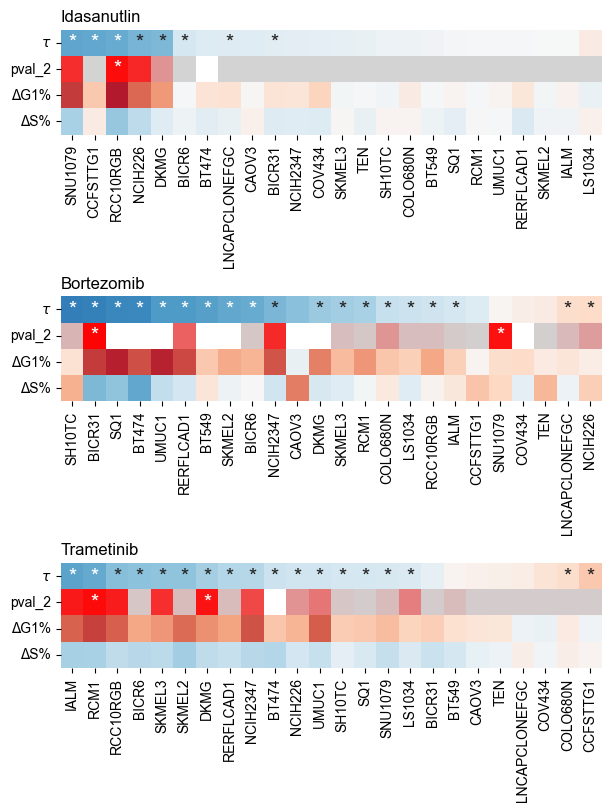

In [51]:
with plt.rc_context({'figure.figsize': (6, 8),'font.sans-serif':['Arial']}):
    fig,axs=plt.subplots(3,1,constrained_layout=True)
    drug_list=['nutlin','bortezomib','trametinib']
    for i in [0,1,2]:
        if i==0:
            heatmap_df=nutlin_heatmap_df
            pval_df=nutlin_pval_df
            drug_name='Idasanutlin'
        elif i==1:
            heatmap_df=bortezomib_heatmap_df
            pval_df=bortezomib_pval_df
            drug_name='Bortezomib'
        else:
            heatmap_df=trametinib_heatmap_df
            pval_df=trametinib_pval_df
            drug_name='Trametinib'
        
        yticks=[r'$\tau$','pval_2','ΔG1%','ΔS%']
        
        data1 = heatmap_df.copy()
        data1.iloc[[1,2,3]] = float('nan')
        sns.heatmap(data1, annot=pval_df,norm=normalize1,yticklabels=yticks, cmap='RdBu_r',cbar=False,annot_kws={"size":15},fmt="",ax=axs[i])

        data2 = heatmap_df.copy()
        data2.iloc[[0,2,3]] = float('nan')
        sns.heatmap(data2,annot=pval_df, norm=normalize2, yticklabels=yticks,cmap=rbcmap,cbar=False,annot_kws={"size":15},fmt="",ax=axs[i])

        data3 = heatmap_df.copy()
        data3.iloc[[0,1,3]] = float('nan')
        sns.heatmap(data3, norm=normalize3,yticklabels=yticks, cmap='RdBu_r',cbar=False,ax=axs[i])
        
        data4 = heatmap_df.copy()
        data4.iloc[[0,1,2]] = float('nan')
        sns.heatmap(data4, norm=normalize3,yticklabels=yticks,cmap='RdBu_r',cbar=False,ax=axs[i])

        axs[i].set_title(drug_name,loc='left')
        axs[i].set_yticklabels(axs[i].get_yticklabels(), rotation=0)
    #plt.savefig('all_figs/cell_cycle/res.svg', format='svg')
    plt.show()

In [ ]:
# bort snu1079
bortezomib_snu1079=bortezomib_adata[bortezomib_adata.obs.cell_type.isin(['SNU1079'])]
sc.tl.pca(bortezomib_snu1079, svd_solver="arpack",random_state=42)
sc.pp.neighbors(bortezomib_snu1079,n_neighbors=10, n_pcs=40,random_state=42)
sc.tl.umap(bortezomib_snu1079,random_state=42)
UMAP_drawing_df = pd.DataFrame(bortezomib_snu1079.obsm['X_umap'],columns=['UMAP1','UMAP2'])
UMAP_drawing_df['condition'] = bortezomib_snu1079.obs.condition.values
UMAP_drawing_df['phase'] = bortezomib_snu1079.obs.phase.values
UMAP_drawing_df.to_csv('bortezomib_snu1079_umap.csv')

In [52]:
UMAP_drawing_df = pd.read_csv('bortezomib_snu1079_umap.csv',index_col=0)

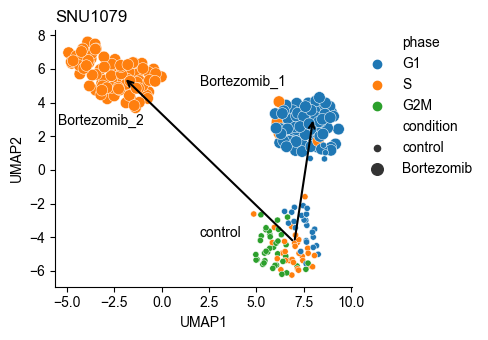

In [53]:
with plt.rc_context({'figure.figsize': (5, 3.5),'font.sans-serif':['Arial']}): 
    ax = sns.scatterplot(
        data=UMAP_drawing_df,
        x="UMAP1",
        y="UMAP2",
        hue="phase",
        size="condition",
        hue_order=["G1", "S", "G2M"],
        size_order=['control','Bortezomib'],
        sizes=[20,70]
    )

    leg = ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
    leg.get_frame().set_linewidth(0)   # remove border
    leg.set_title("") 
    plt.text(2,-4,'control',fontsize=10)
    plt.text(-5.5,2.7,'Bortezomib_2',fontsize=10)
    plt.text(2,5,'Bortezomib_1',fontsize=10)
    plt.annotate(
    '', xy=(-2, 5.5), xytext=(7, -4.3),
    arrowprops=dict(arrowstyle='->', linewidth=1.5)
)
    plt.annotate(
    '', xy=(8, 3.1), xytext=(7, -4.3),
    arrowprops=dict(arrowstyle='->', linewidth=1.5)
)
    plt.title(
    'SNU1079',
    loc='left'           
)
    sns.despine()
    plt.tight_layout()
    plt.show()

In [56]:
data_df=(pd.DataFrame([list(bortezomib_adata.obs.S_markers),
                       list(bortezomib_adata.obs.condition),
                       list(bortezomib_adata.obs.cell_type)])).T
data_df.columns=['Yobs','pert','group']
pert_dict={'Bortezomib':1,'control':0}
data_df["pert"].replace(pert_dict, inplace=True)
data_df = data_df[data_df.group=='SNU1079']

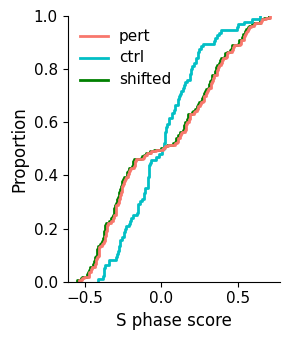

In [57]:
shifted_df=data_df[data_df.pert==1].copy()
data0_obs=(data_df[data_df.pert==0])['Yobs'].values
data1_obs=(data_df[data_df.pert==1])['Yobs'].values
tau_hat=np.mean(data1_obs)-np.mean(data0_obs)
shifted_df['Yobs']=shifted_df['Yobs']-tau_hat
shifted_df['pert']=2
data_df_drawcdf=pd.concat([data_df, shifted_df], ignore_index=True, sort=False)
rename_dict = {0: 'ctrl', 1: 'pert', 2: 'shifted'}
data_df_drawcdf['pert'] = data_df_drawcdf['pert'].replace(rename_dict)

# set color
palette = {
    'ctrl': '#02BFC5',
    'pert': '#F8776C',
    'shifted': 'g'
}

# set fig
plt.figure(figsize=(3, 3.5))
ax = sns.ecdfplot(data=data_df_drawcdf, x="Yobs", hue="pert", palette=palette, linewidth=2)
sns.despine()
legend = ax.legend_
if legend:
    legend.set_frame_on(False)
    legend.set_title(None) 
    for text in legend.get_texts():
        text.set_fontsize(11)  

plt.xlabel('S phase score', fontsize=12)
plt.ylabel('Proportion',fontsize=12)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.tight_layout()
plt.show()

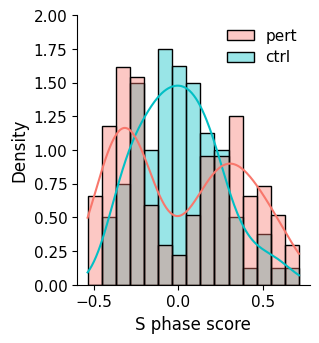

In [60]:
rename_dict = {0: 'ctrl', 1: 'pert'}
data_df['pert'] = data_df['pert'].replace(rename_dict)
# set color
palette = {
    'ctrl': '#02BFC5',
    'pert': '#F8776C'
}
plt.figure(figsize=(3, 3.5))
ax = sns.histplot(
    data=data_df,
    x="Yobs",
    hue="pert",
    kde=True,
    stat="density",
    palette=palette,
    common_norm=False,
    alpha=0.4,
    bins=15
)

sns.despine()
legend = ax.legend_
if legend:
    legend.set_frame_on(False)
    legend.set_title(None) 
    for text in legend.get_texts():
        text.set_fontsize(11)  

plt.xlabel('S phase score', fontsize=12)
plt.ylabel('Density',fontsize=12)
plt.ylim([0,2])
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.show()